In [ ]:
# ─────────────────────────────────────────────────────────────────
# Utility: Increase the font size of the notebook UI for readability
# ─────────────────────────────────────────────────────────────────
# This is a helper that injects custom JavaScript into the notebook
# to override the default body font-size. It runs automatically
# before every cell execution (pre_run_cell event).
def increase_font():
  # Import Javascript display helper from IPython (used to run JS in browser)
  from IPython.display import Javascript
  # Inject JS: loop through CSS rules of first stylesheet and bump
  # the body font size to 30px for better visibility during teaching/demos.
  display(Javascript('''
  for (rule of document.styleSheets[0].cssRules){
    if (rule.selectorText=='body') {
      rule.style.fontSize = '30px'
      break
    }
  }
  '''))

# Register the function so it fires every time a cell is about to run
get_ipython().events.register('pre_run_cell', increase_font)


In [ ]:
# List every Python package currently installed in this environment
# Useful to verify that tensorflow/keras/sklearn/etc. are available.
! pip list


<IPython.core.display.Javascript object>

Package                                  Version
---------------------------------------- ------------------
absl-py                                  1.4.0
accelerate                               1.13.0
access                                   1.1.10.post3
affine                                   2.4.0
aiofiles                                 24.1.0
aiohappyeyeballs                         2.6.1
aiohttp                                  3.13.5
aiosignal                                1.4.0
aiosqlite                                0.22.1
alabaster                                1.0.0
albucore                                 0.0.24
albumentations                           2.0.8
ale-py                                   0.11.2
alembic                                  1.18.4
altair                                   5.5.0
annotated-doc                            0.0.4
annotated-types                          0.7.0
antlr4-python3-runtime                   4.9.3
anyio                          

In [ ]:
# Install TensorFlow (deep-learning framework) and Keras (high-level API).
# Commented out because Google Colab ships with these pre-installed.
# Uncomment and run this line if you're on a fresh environment.
# pip install tensorflow keras


<IPython.core.display.Javascript object>

In [ ]:
# ── Core data-science libraries ─────────────────────────────────
import pandas as pd              # DataFrames / tabular data handling
import numpy as np               # Numerical arrays and math operations
import matplotlib.pyplot as plt  # Low-level plotting library
import seaborn as sns            # High-level statistical visualisation (built on matplotlib)

# Jupyter magic: render matplotlib charts inline inside the notebook
%matplotlib inline


<IPython.core.display.Javascript object>

In [ ]:
# ── Deep-learning stack: TensorFlow + Keras ─────────────────────
import tensorflow as tf                      # Main TF package (backend engine)
from tensorflow import keras                 # Keras: high-level neural network API
from tensorflow.keras import Layer           # Base class for building custom layers
from tensorflow.keras.layers import Dense    # Dense = fully-connected neural network layer
from tensorflow.keras import Sequential      # Sequential = linear stack of layers (simplest model type)

# Print the TF version to confirm install + reproducibility
print("TensorFlow version:", tf.__version__)


<IPython.core.display.Javascript object>

TensorFlow version: 2.19.0


In [ ]:
# ── scikit-learn helpers for classical ML preprocessing ─────────
from sklearn.model_selection import train_test_split  # Split data into train/test sets
from sklearn.preprocessing import StandardScaler      # Feature scaling (mean=0, std=1)


<IPython.core.display.Javascript object>

In [ ]:
# Load the FEATURES dataset (input variables X) from Google Drive
# CSV contains academic details of Indian engineering students.
X = pd.read_csv(r"/content/drive/MyDrive/DataScience_11_AM_Kalyan_nagar/datasets/indian_engineering_student_placement.csv")


<IPython.core.display.Javascript object>

In [ ]:
# Mount Google Drive so the notebook can read/write files stored there.
# After running, Drive appears at /content/drive in the Colab filesystem.
from google.colab import drive
drive.mount('/content/drive')


In [ ]:
# Load the TARGET dataset (label column Y) — placement outcome for each student.
Y = pd.read_csv(r"/content/drive/MyDrive/DataScience_11_AM_Kalyan_nagar/datasets/placement_targets.csv")


<IPython.core.display.Javascript object>

In [ ]:
# Select only the 6 input features we want the model to learn from.
# These are believed to influence placement success.
X = X[['study_hours_per_day','tenth_percentage', 'twelfth_percentage' ,'cgpa','internships_completed','projects_completed']]


<IPython.core.display.Javascript object>

In [ ]:
# Encode the target column into binary form (1 = Placed, 0 = Not Placed).
# Neural networks need numeric labels, not strings.
Y = Y[['placement_status']].map(lambda x:1 if x == "Placed" else 0)


<IPython.core.display.Javascript object>

In [ ]:
# Quick preview of the feature DataFrame (rows × 6 columns)
X


<IPython.core.display.Javascript object>

,study_hours_per_day,tenth_percentage,twelfth_percentage,cgpa,internships_completed,projects_completed
0,3.8,74.0,75.0,8.74,3,7
1,6.3,75.3,69.7,7.80,1,5
2,1.5,62.8,68.3,6.95,2,8
3,4.7,57.9,51.4,7.46,2,6
4,5.2,61.3,73.5,6.86,3,3
...,...,...,...,...,...,...
4995,3.7,90.4,98.3,10.00,3,6
4996,6.3,74.3,72.6,7.76,4,4
4997,2.0,64.0,71.2,7.79,1,6
4998,5.1,74.3,74.0,8.76,4,6


In [ ]:
# Confirm the exact feature names in order — useful later when interpreting weights
X.columns


<IPython.core.display.Javascript object>

Index(['study_hours_per_day', 'tenth_percentage', 'twelfth_percentage', 'cgpa',
       'internships_completed', 'projects_completed'],
      dtype='object')

In [ ]:
# Preview the target variable (should only contain 0s and 1s now)
Y


<IPython.core.display.Javascript object>

,placement_status
0,1
1,1
2,1
3,1
4,1
...,...
4995,1
4996,0
4997,1
4998,1


In [ ]:
# ── Build the Artificial Neural Network (ANN) architecture ──────
# Sequential = layers stacked one after another (input → hidden → output)
model  = Sequential()

# Input layer + 1st hidden layer:
#   units=6        → 6 neurons in this hidden layer
#   activation=relu→ ReLU: f(x)=max(0,x), introduces non-linearity
#   input_dim=6    → tells Keras the input has 6 features (only needed on 1st layer)
model.add(Dense(units=6, activation='relu', input_dim=6))  #input_layer-> 6 and Hidden_layer1 --> 6

# 2nd hidden layer: another 6 ReLU neurons to learn deeper patterns
model.add(Dense(units=6, activation='relu')) # Hidden_layer2 --> 6

# Output layer:
#   units=1            → one neuron for binary classification
#   activation=sigmoid → squashes output to (0,1) — interpret as probability of "Placed"
model.add(Dense(units=1, activation='sigmoid')) # output_layer  --> 1


<IPython.core.display.Javascript object>

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
# Compile = configure the learning process before training
#   optimizer='rmsprop'           → adaptive gradient-descent algorithm (good default)
#   loss='binary_crossentropy'    → standard loss for 2-class problems
#   metrics=['accuracy']          → track accuracy during training / evaluation
model.compile(optimizer='rmsprop', loss= 'binary_crossentropy', metrics=['accuracy'])


<IPython.core.display.Javascript object>

In [ ]:
# Print the network architecture: layer types, output shape, parameter counts.
# Great for sanity-checking dimensions and total trainable weights.
model.summary()


<IPython.core.display.Javascript object>

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 6)              │            42 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 6)              │            42 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │             7 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 91 (364.00 B)

 Trainable params: 91 (364.00 B)

 Non-trainable params: 0 (0.00 B)

## Step 4b: Split Into Training and Testing Sets

The **training set** is the data the model learns from, like practice problems.

The **testing set** is held back to check how well the model learned, like a final exam.

In [ ]:
# Split the dataset into training and testing subsets.
# Default: 75% training, 25% testing. Testing data is held out so we
# can evaluate how well the model generalises to unseen samples.
X_train, X_test, y_train, y_test = train_test_split(X,Y)


<IPython.core.display.Javascript object>

In [ ]:
# Inspect shapes to confirm the split was done correctly
# (rows_train, 6), (rows_test, 6), (rows_train, 1), (rows_test, 1)
X_train.shape, X_test.shape, y_train.shape, y_test.shape


<IPython.core.display.Javascript object>

((3750, 6), (1250, 6), (3750, 1), (1250, 1))

## Step 4c: Feature Scaling (Normalization)

`StandardScaler` converts feature values to a common scale with mean `0` and standard deviation `1`.

Formula:

$$z = \frac{x - \text{mean}}{\text{std}}$$

Important: fit the scaler only on the training data, then transform both training and testing data. This prevents data leakage.

In [ ]:
# Instantiate the scaler object
Std_Scaler = StandardScaler()

# fit_transform on TRAIN: learns mean/std from training data AND scales it
X_train_transformed = Std_Scaler.fit_transform(X_train)  # Learn + transform
# transform on TEST: reuse the SAME mean/std (no refitting) — prevents data leakage
X_test_transformed = Std_Scaler.transform(X_test)        # transform


<IPython.core.display.Javascript object>

In [ ]:
# Peek at the scaled training data — values should now be roughly between -3 and +3
X_train_transformed


<IPython.core.display.Javascript object>

array([[ 1.08458322, -0.35854142, -1.12764795, -1.11957024,  0.75595978,
        -0.74920152],
       [ 0.07353678,  1.07638956,  0.96031084,  0.77976806, -0.12333587,
        -1.23704762],
       [ 0.1240891 , -1.72514235, -2.38042322, -1.84171449, -1.00263152,
        -0.26135542],
       ...,
       [ 1.4890018 ,  1.70112141,  1.53328557,  1.69976005,  1.63525544,
         1.20218289],
       [-0.68474806,  0.23690613, -0.02054422,  0.58192032, -0.12333587,
         0.71433679],
       [-1.64524218, -2.3205899 , -2.00167721, -1.56472765, -0.12333587,
         0.71433679]])

## Training the Model

In [ ]:
# ── Train the neural network ────────────────────────────────────
# fit() returns a `history` object containing loss/accuracy per epoch.
history = model.fit(
    X_train_transformed, y_train,  # Scaled features + binary labels
    epochs=100,                    # One epoch = one full pass over training data
    batch_size=32,                 # Mini-batch size: weights updated every 32 samples
    validation_split=0.15,         # Hold out 15% of training data to monitor overfitting
    verbose=1                      # 1 = show progress bar, 0 = silent, 2 = one line/epoch
)


<IPython.core.display.Javascript object>

Epoch 1/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7248 - loss: 0.5891 - val_accuracy: 0.8455 - val_loss: 0.4888
Epoch 2/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8604 - loss: 0.4289 - val_accuracy: 0.8526 - val_loss: 0.3899
Epoch 3/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8613 - loss: 0.3683 - val_accuracy: 0.8526 - val_loss: 0.3621
Epoch 4/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8613 - loss: 0.3475 - val_accuracy: 0.8526 - val_loss: 0.3516
Epoch 5/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8613 - loss: 0.3365 - val_accuracy: 0.8526 - val_loss: 0.3442
Epoch 6/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8613 - loss: 0.3296 - val_accuracy: 0.8526 - val_loss: 0.3398
Epoch 7/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8613 - loss: 0.3256 - val_accuracy: 0.8526 - val_loss: 0.3374
Epoch 8/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8613 - loss: 0.3233 - val_accu

In [ ]:
# Inspect the training history — each is a list with one value per epoch.
history.history['accuracy']      # Training accuracy per epoch
history.history['loss']          # Training loss per epoch
history.history['val_accuracy']  # Validation accuracy per epoch
history.history['val_loss']      # Validation loss per epoch


<IPython.core.display.Javascript object>

[0.48883095383644104,
 0.3898707330226898,
 0.3621377944946289,
 0.3515666127204895,
 0.3441767692565918,
 0.3398306369781494,
 0.3373972475528717,
 0.3371362090110779,
 0.33579376339912415,
 0.3348810374736786,
 0.33455178141593933,
 0.33426791429519653,
 0.3340575098991394,
 0.3336501717567444,
 0.33334478735923767,
 0.33294805884361267,
 0.33258190751075745,
 0.3327306807041168,
 0.3321014940738678,
 0.3310236930847168,
 0.330777645111084,
 0.3306676149368286,
 0.33021968603134155,
 0.3297472596168518,
 0.32995155453681946,
 0.33078470826148987,
 0.3299153447151184,
 0.3292539417743683,
 0.3296307623386383,
 0.32936200499534607,
 0.3291674554347992,
 0.3287581205368042,
 0.32958102226257324,
 0.3291175365447998,
 0.329373836517334,
 0.32886165380477905,
 0.32948604226112366,
 0.32996582984924316,
 0.32963550090789795,
 0.3292945325374603,
 0.32935184240341187,
 0.3294767439365387,
 0.3293188810348511,
 0.3292582035064697,
 0.3296329081058502,
 0.3291192948818207,
 0.3295474052429199

<IPython.core.display.Javascript object>

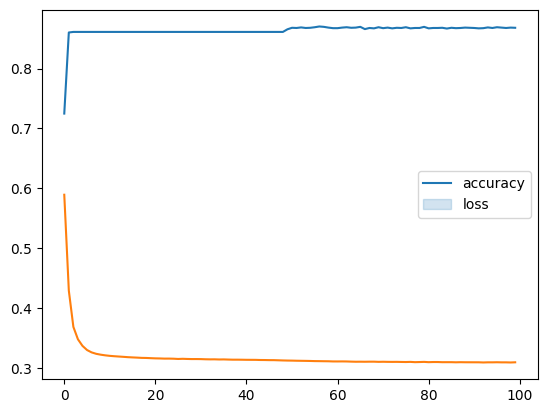

In [ ]:
# Plot TRAINING accuracy vs loss across epochs.
# Expectation: accuracy ↑ and loss ↓ as the model learns.
sns.lineplot(history.history['accuracy'])
sns.lineplot(history.history['loss'])
plt.legend(['accuracy','loss' ])
plt.show()


<IPython.core.display.Javascript object>

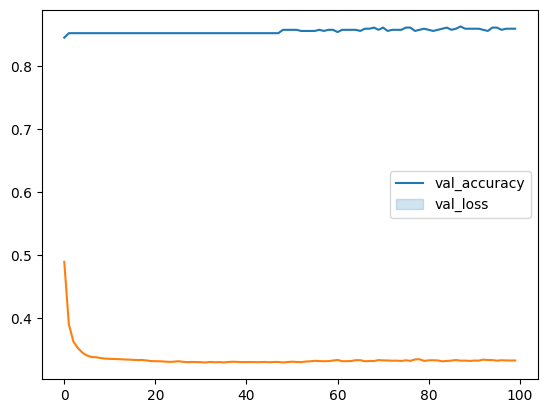

In [ ]:
# Plot VALIDATION accuracy vs loss — watch for divergence from training curves
# (big gap usually indicates overfitting).
sns.lineplot(history.history['val_accuracy'])
sns.lineplot(history.history['val_loss'])
plt.legend(['val_accuracy','val_loss' ])
plt.show()


In [ ]:
# Evaluate the trained model on the completely unseen TEST set.
# Returns [loss, accuracy]. verbose=0 suppresses per-batch logs.
test_loss, test_accuracy = model.evaluate(X_test_transformed, y_test, verbose=0)


<IPython.core.display.Javascript object>

In [ ]:
# Display the final test-set metrics for the model
test_accuracy, test_loss


<IPython.core.display.Javascript object>

(0.8759999871253967, 0.30310890078544617)

<IPython.core.display.Javascript object>

40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


/tmp/ipykernel_2634/1295443442.py:13: UserWarning: Glyph 128306 (\N{BLACK SQUARE BUTTON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128306 (\N{BLACK SQUARE BUTTON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


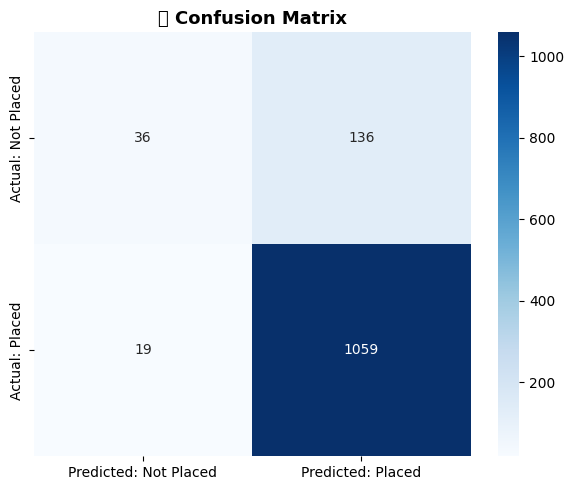

In [ ]:
# ── Detailed model evaluation using a Confusion Matrix ──────────
from sklearn.metrics import classification_report, confusion_matrix

# Step 1: Get raw probability outputs from the sigmoid layer (range 0-1)
y_pred_prob = model.predict(X_test_transformed)         # Get probabilities (0 to 1)
# Step 2: Convert probabilities → hard class labels using 0.5 threshold
y_pred      = (y_pred_prob > 0.5).astype(int)      # Convert to 0 or 1 (threshold=0.5)

# Step 3: Build the confusion matrix (rows = actual, cols = predicted)
#   [[TN  FP]
#    [FN  TP]]
cm = confusion_matrix(y_test, y_pred)

# Step 4: Visualise the confusion matrix as an annotated heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted: Not Placed', 'Predicted: Placed'],
            yticklabels=['Actual: Not Placed', 'Actual: Placed'])
plt.title('🔲 Confusion Matrix', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


# NLP

In [ ]:
# NLP section starts here — re-import core libs for a clean slate
import pandas as pd
import numpy as np


<IPython.core.display.Javascript object>

In [ ]:
# Load a CSV of product reviews — each row contains a text review we'll clean and analyse
reviews_df = pd.read_csv("/content/product_reviews.csv")


<IPython.core.display.Javascript object>

In [ ]:
# Preview the reviews DataFrame (check columns + sample rows)
reviews_df


<IPython.core.display.Javascript object>

,review_id,product,review_text,sentiment
0,1,Smartphone,I absolutely LOVE this phone!!! The camera is ...,good
1,2,Smartphone,Worst phone I have ever bought... screen crack...,bad
2,3,Smartphone,"The phone is okay, nothing special. Works as e...",neutral
3,4,Headphones,Sound quality is superb!! Bass is deep & cryst...,good
4,5,Headphones,These headphones broke after 1 week of use. Ve...,bad
5,6,Headphones,Decent headphones. Not the best but not bad ei...,neutral
6,7,Laptop,"Super fast laptop, boots up in seconds!! Perfe...",good
7,8,Laptop,Laptop heats up like crazy and fan is soooo lo...,bad
8,9,Laptop,Average laptop. Does the job but nothing extra...,neutral
9,10,Shoes,Best running shoes ever!!! So comfy and stylis...,good


In [ ]:
# In NLP terminology, a "corpus" is a collection of text documents.
# Convert the review_text column into a plain Python list of strings.
corpus = reviews_df['review_text'].to_list()


<IPython.core.display.Javascript object>

In [ ]:
# Print the entire corpus (list of review strings) to eyeball the raw text
corpus


<IPython.core.display.Javascript object>

['I absolutely LOVE this phone!!! The camera is amazing 😍 and battery lasts all day. Best purchase ever!!!',
 'Worst phone I have ever bought... screen cracked in 2 days :( totally disappointed.',
 'The phone is okay, nothing special. Works as expected for the price.',
 'Sound quality is superb!! Bass is deep & crystal clear 🎧 highly recommended.',
 'These headphones broke after 1 week of use. Very poor build quality!!',
 'Decent headphones. Not the best but not bad either.',
 'Super fast laptop, boots up in seconds!! Perfect for work & gaming 💻',
 'Laptop heats up like crazy and fan is soooo loud. Waste of money.',
 'Average laptop. Does the job but nothing extraordinary.',
 'Best running shoes ever!!! So comfy and stylish 👟 love love love!',
 'Shoes started tearing after 10 days. Terrible quality :(',
 'Shoes are fine. Fits well. Color is slightly different from the picture.',
 'Gorgeous watch!! Looks premium and works perfectly. 5 stars ⭐⭐⭐⭐⭐',
 "Don't buy this watch!!! Battery died

In [ ]:
# Pick the FIRST document from the corpus — we'll use it to demo cleaning steps
doc_1 = corpus[0]
doc_1


<IPython.core.display.Javascript object>

'I absolutely LOVE this phone!!! The camera is amazing 😍 and battery lasts all day. Best purchase ever!!!'

In [ ]:
# STEP 1 of text cleaning → Normalise case.
# Lowercasing ensures "Good" and "good" are treated as the same token.
lower_text = doc_1.lower()
lower_text


<IPython.core.display.Javascript object>

'i absolutely love this phone!!! the camera is amazing 😍 and battery lasts all day. best purchase ever!!!'

In [ ]:
# Sample sentence used to demonstrate regex pattern matching for emails
'hi i am kumar my email is kumar@gmail.com'


In [ ]:
# Simple regex to detect emails ending in .com
# [a-zA-Z0-9]+ → one or more alphanumeric chars, then literal '@' then '.com'
email_pattern = r'[a-zA-Z0-9]+@.com'


In [ ]:
# STEP 2 of text cleaning → Remove special characters / punctuation.
# Using regex we extract only alphanumeric "word" tokens. Everything else
# (spaces, commas, emojis, punctuation) is discarded.
import re

# Pattern matches runs of letters or digits
remove_spec_chars_pat = r'[a-zA-Z0-9]+'

# findall → returns a list of all matching substrings (our tokens)
result = re.findall(pattern= remove_spec_chars_pat, string = lower_text)


<IPython.core.display.Javascript object>

In [ ]:
# Inspect the tokenised list of words after special-character removal
result


<IPython.core.display.Javascript object>

['i',
 'absolutely',
 'love',
 'this',
 'phone',
 'the',
 'camera',
 'is',
 'amazing',
 'and',
 'battery',
 'lasts',
 'all',
 'day',
 'best',
 'purchase',
 'ever']

In [ ]:
# STEP 3 of text cleaning → Remove stopwords (is, the, a, of, and ...).
# Stopwords carry little meaning for most NLP tasks so we drop them.
import nltk
from nltk.corpus import stopwords

# One-time download of the stopwords corpus (≈ a few KB)
nltk.download('stopwords')

# Load the English stopword list into a Python list
stop_words = stopwords.words('english')
print(stop_words)


<IPython.core.display.Javascript object>

['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't", 'd', 'did', 'didn', "didn't", 'do', 'does', 'doesn', "doesn't", 'doing', 'don', "don't", 'down', 'during', 'each', 'few', 'for', 'from', 'further', 'had', 'hadn', "hadn't", 'has', 'hasn', "hasn't", 'have', 'haven', "haven't", 'having', 'he', "he'd", "he'll", 'her', 'here', 'hers', 'herself', "he's", 'him', 'himself', 'his', 'how', 'i', "i'd", 'if', "i'll", "i'm", 'in', 'into', 'is', 'isn', "isn't", 'it', "it'd", "it'll", "it's", 'its', 'itself', "i've", 'just', 'll', 'm', 'ma', 'me', 'mightn', "mightn't", 'more', 'most', 'mustn', "mustn't", 'my', 'myself', 'needn', "needn't", 'no', 'nor', 'not', 'now', 'o', 'of', 'off', 'on', 'once', 'only', 'or', 'other', 'our', 'ours', 'ourselves', 'out', 'over', 'own', 're', 's', 'same', 'shan', "shan't", 'she

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:
# Rebuild the document by keeping ONLY the tokens that are NOT stopwords
cleaned_text = ""

for word in result:
  # Keep the word only if it is a meaningful (non-stopword) token
  if word not in stop_words:
    cleaned_text += word
    cleaned_text += " "   # add a space so tokens remain separated

cleaned_text


<IPython.core.display.Javascript object>

'absolutely love phone camera amazing battery lasts day best purchase ever '

In [ ]:
# ── Reusable text-cleaning helper ───────────────────────────────
# Combines all 3 cleaning steps into a single function we can apply
# to every review in the corpus.
def text_cleaner(text):

  # Pattern for alphanumeric tokens (drops punctuation / special chars)
  remove_spec_chars_pat = r'[a-zA-Z0-9]+'

  # 1) Lowercase
  lower_text = text.lower()
  # 2) Tokenise + remove special chars
  result = re.findall(pattern= remove_spec_chars_pat, string = lower_text)

  # 3) Remove stopwords and re-join the remaining tokens
  cleaned_text = ""

  for word in result:

    if word not in stop_words:
      cleaned_text += word
      cleaned_text += " "

  return cleaned_text


<IPython.core.display.Javascript object>

In [ ]:
# Apply the cleaner to every document in the corpus and print the result.
# Quick visual check that cleaning works across all reviews.
for document in corpus:
  print(text_cleaner(document))


<IPython.core.display.Javascript object>

I absolutely LOVE this phone!!! The camera is amazing 😍 and battery lasts all day. Best purchase ever!!!
Worst phone I have ever bought... screen cracked in 2 days :( totally disappointed.
The phone is okay, nothing special. Works as expected for the price.
Sound quality is superb!! Bass is deep & crystal clear 🎧 highly recommended.
These headphones broke after 1 week of use. Very poor build quality!!
Decent headphones. Not the best but not bad either.
Super fast laptop, boots up in seconds!! Perfect for work & gaming 💻
Laptop heats up like crazy and fan is soooo loud. Waste of money.
Average laptop. Does the job but nothing extraordinary.
Best running shoes ever!!! So comfy and stylish 👟 love love love!
Shoes started tearing after 10 days. Terrible quality :(
Shoes are fine. Fits well. Color is slightly different from the picture.
Gorgeous watch!! Looks premium and works perfectly. 5 stars ⭐⭐⭐⭐⭐
Don't buy this watch!!! Battery died in 3 days. Complete junk.
It's an okay watch. Does wh

In [ ]:
# Concatenate every cleaned review into a SINGLE long string.
# This aggregated text will later be split into a vocabulary.
complete_documents = ""

for document in corpus:
  print(text_cleaner(document))
  complete_documents += text_cleaner(document)


<IPython.core.display.Javascript object>

absolutely love phone camera amazing battery lasts day best purchase ever 
worst phone ever bought screen cracked 2 days totally disappointed 
phone okay nothing special works expected price 
sound quality superb bass deep crystal clear highly recommended 
headphones broke 1 week use poor build quality 
decent headphones best bad either 
super fast laptop boots seconds perfect work gaming 
laptop heats like crazy fan soooo loud waste money 
average laptop job nothing extraordinary 
best running shoes ever comfy stylish love love love 
shoes started tearing 10 days terrible quality 
shoes fine fits well color slightly different picture 
gorgeous watch looks premium works perfectly 5 stars 
buy watch battery died 3 days complete junk 
okay watch watch 
amazing camera pictures come crisp colorful worth every penny 
camera stopped working month customer service horrible 
camera decent beginners professional use though 
super spacious sturdy backpack perfect college highly recommend 
zipper

In [ ]:
# Display the full aggregated cleaned text
complete_documents


<IPython.core.display.Javascript object>

' absolutely love phone camera amazing battery lasts day best purchase ever worst phone ever bought screen cracked 2 days totally disappointed phone okay nothing special works expected price sound quality superb bass deep crystal clear highly recommended headphones broke 1 week use poor build quality decent headphones best bad either super fast laptop boots seconds perfect work gaming laptop heats like crazy fan soooo loud waste money average laptop job nothing extraordinary best running shoes ever comfy stylish love love love shoes started tearing 10 days terrible quality shoes fine fits well color slightly different picture gorgeous watch looks premium works perfectly 5 stars buy watch battery died 3 days complete junk okay watch watch amazing camera pictures come crisp colorful worth every penny camera stopped working month customer service horrible camera decent beginners professional use though super spacious sturdy backpack perfect college highly recommend zipper broke day 2 wast

In [ ]:
# Split the aggregated string on whitespace → list of all tokens (with duplicates)
complete_documents.split()


<IPython.core.display.Javascript object>

['absolutely',
 'love',
 'phone',
 'camera',
 'amazing',
 'battery',
 'lasts',
 'day',
 'best',
 'purchase',
 'ever',
 'worst',
 'phone',
 'ever',
 'bought',
 'screen',
 'cracked',
 '2',
 'days',
 'totally',
 'disappointed',
 'phone',
 'okay',
 'nothing',
 'special',
 'works',
 'expected',
 'price',
 'sound',
 'quality',
 'superb',
 'bass',
 'deep',
 'crystal',
 'clear',
 'highly',
 'recommended',
 'headphones',
 'broke',
 '1',
 'week',
 'use',
 'poor',
 'build',
 'quality',
 'decent',
 'headphones',
 'best',
 'bad',
 'either',
 'super',
 'fast',
 'laptop',
 'boots',
 'seconds',
 'perfect',
 'work',
 'gaming',
 'laptop',
 'heats',
 'like',
 'crazy',
 'fan',
 'soooo',
 'loud',
 'waste',
 'money',
 'average',
 'laptop',
 'job',
 'nothing',
 'extraordinary',
 'best',
 'running',
 'shoes',
 'ever',
 'comfy',
 'stylish',
 'love',
 'love',
 'love',
 'shoes',
 'started',
 'tearing',
 '10',
 'days',
 'terrible',
 'quality',
 'shoes',
 'fine',
 'fits',
 'well',
 'color',
 'slightly',
 'differen

In [ ]:
# Store that token list as our vocabulary
# NOTE: to get UNIQUE words only, wrap with set(...)  -> set(complete_documents.split())
vocabulary = (complete_documents.split())


<IPython.core.display.Javascript object>

In [ ]:
# Display the final vocabulary — input for future steps like
# Bag-of-Words, TF-IDF, or building word embeddings.
vocabulary


<IPython.core.display.Javascript object>

['absolutely',
 'love',
 'phone',
 'camera',
 'amazing',
 'battery',
 'lasts',
 'day',
 'best',
 'purchase',
 'ever',
 'worst',
 'phone',
 'ever',
 'bought',
 'screen',
 'cracked',
 '2',
 'days',
 'totally',
 'disappointed',
 'phone',
 'okay',
 'nothing',
 'special',
 'works',
 'expected',
 'price',
 'sound',
 'quality',
 'superb',
 'bass',
 'deep',
 'crystal',
 'clear',
 'highly',
 'recommended',
 'headphones',
 'broke',
 '1',
 'week',
 'use',
 'poor',
 'build',
 'quality',
 'decent',
 'headphones',
 'best',
 'bad',
 'either',
 'super',
 'fast',
 'laptop',
 'boots',
 'seconds',
 'perfect',
 'work',
 'gaming',
 'laptop',
 'heats',
 'like',
 'crazy',
 'fan',
 'soooo',
 'loud',
 'waste',
 'money',
 'average',
 'laptop',
 'job',
 'nothing',
 'extraordinary',
 'best',
 'running',
 'shoes',
 'ever',
 'comfy',
 'stylish',
 'love',
 'love',
 'love',
 'shoes',
 'started',
 'tearing',
 '10',
 'days',
 'terrible',
 'quality',
 'shoes',
 'fine',
 'fits',
 'well',
 'color',
 'slightly',
 'differen

## Step: Tokenization

Tokenization means splitting raw text into smaller units called **tokens**.

- **Word tokenization** breaks a sentence into individual words.
- **Sentence tokenization** breaks a paragraph into individual sentences.

NLTK tokenizers are smarter than `.split()` because they handle punctuation, contractions like `don't`, abbreviations, and similar language details.

In [ ]:
# Download the tokenizer models (one-time download)
nltk.download('punkt')
nltk.download('punkt_tab')

from nltk.tokenize import word_tokenize, sent_tokenize

# Use the FIRST raw review from our corpus as the demo document
sample_text = corpus[0]
sample_text


In [ ]:
# Sentence tokenization → list of sentences
sentences = sent_tokenize(sample_text)
print("Number of sentences:", len(sentences))
sentences


In [ ]:
# Word tokenization → list of word/punctuation tokens
words = word_tokenize(sample_text)
print("Number of word tokens:", len(words))
words


## Step: Normalization (Stemming and Lemmatization)

Normalization reduces different forms of a word to a single base form so the model treats them as the same token.

**Stemming** is rule-based suffix chopping.

Examples: `playing`, `played`, `plays` -> `play`

It is fast, but it may produce non-real words, such as `studies` -> `studi`.

**Lemmatization** is dictionary-based and returns the actual root word, called the lemma.

Examples: `better` -> `good`, `running` -> `run`

It is slower than stemming, but more linguistically accurate.

In [ ]:
# Stemming with the Porter algorithm (most common stemmer)
from nltk.stem import PorterStemmer

stemmer = PorterStemmer()

# Clean the sample first (lowercase + remove special chars + stopwords),
# then split into words so we stem only meaningful tokens.
cleaned_words = text_cleaner(sample_text).split()

stemmed_words = [stemmer.stem(w) for w in cleaned_words]
print("Original :", cleaned_words)
print("Stemmed  :", stemmed_words)


In [ ]:
# Lemmatization with WordNet (returns real dictionary words)
nltk.download('wordnet')
nltk.download('omw-1.4')

from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()

# pos='v' → treat tokens as verbs, gives better results for
# words like "running" → "run", "studies" → "study".
lemmatized_words = [lemmatizer.lemmatize(w, pos='v') for w in cleaned_words]
print("Original    :", cleaned_words)
print("Lemmatized  :", lemmatized_words)


## Step: POS Tagging (Parts of Speech)

POS tagging assigns a grammatical category to each token.

Common tags:

- `NN`: noun
- `VB`: verb
- `JJ`: adjective
- `RB`: adverb
- `PRP`: pronoun
- `IN`: preposition

POS tagging is useful for understanding sentence structure and is often used before tasks like NER, chunking, and better lemmatization.

In [ ]:
# Download the POS tagger model (one-time)
nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')

from nltk import pos_tag

# Tag each token from our word_tokenize output with its POS label
pos_tags = pos_tag(words)
pos_tags


## Step: Named Entity Recognition (NER)

NER identifies and classifies **named entities** inside text.

Examples of entity types:

- `PERSON`: `Elon Musk`, `Kumar`
- `ORGANIZATION`: `Google`, `NASA`
- `GPE`: geo-political entities such as `India` or `New York`
- `DATE`, `TIME`, `MONEY`, `PERCENT`, and more

Here we use NLTK's `ne_chunk`, which works on POS-tagged tokens.

In [ ]:
# Download NER models (one-time)
nltk.download('maxent_ne_chunker')
nltk.download('maxent_ne_chunker_tab')
nltk.download('words')

from nltk import ne_chunk

# ne_chunk takes POS-tagged tokens and returns a Tree where named
# entities are grouped sub-trees labelled with their entity type.
ner_tree = ne_chunk(pos_tags)
ner_tree


In [ ]:
# Extract just the named entities (sub-trees) from the parse tree
named_entities = []
for chunk in ner_tree:  
    # A sub-tree means NLTK detected a named entity
    if hasattr(chunk, 'label'):
        entity_text = " ".join(token for token, pos in chunk.leaves())
        named_entities.append((entity_text, chunk.label()))

print("Detected named entities:")
named_entities


## Optional: Better NER With spaCy

spaCy ships with a pre-trained statistical NER model that is usually more accurate than NLTK's model.

Run the next cell only if spaCy and the English model are available.

In [ ]:
# Uncomment if spaCy / the English model isn't installed yet.
# !pip install spacy
# !python -m spacy download en_core_web_sm

import spacy

# Load the small English pipeline (tokenizer + tagger + parser + NER)
nlp = spacy.load("en_core_web_sm")

doc = nlp(sample_text)

# Print every detected entity along with its type
for ent in doc.ents:
    print(f"{ent.text:<25} → {ent.label_}")


## Word2Vec: Teaching a Computer the Meaning of Words

**The big idea:** words that appear in **similar contexts** should have **similar vectors**.

Computers do not understand text directly; they understand numbers. Word2Vec converts every word into a list of numbers, called a **vector**. For example, one word may be represented by 100 numbers. Words with related meanings end up close together in that vector space.

### Tiny Intuition Example

Look at these sentences:

```text
1. The king ruled the kingdom.
2. The queen ruled the kingdom.
3. The man walked to the market.
4. The woman walked to the market.
```

- `king` and `queen` appear with similar neighbours, such as `ruled` and `kingdom`, so Word2Vec gives them similar vectors.
- `man` and `woman` appear with similar neighbours, such as `walked` and `market`, so their vectors also become similar.

### Vector Arithmetic

Once trained, Word2Vec vectors can do math on meaning:

$$\text{king} - \text{man} + \text{woman} \approx \text{queen}$$

The model learns relationships like gender and royalty from sentence context, without being explicitly told those concepts.

### Two Flavours of Word2Vec

| Variant | What it predicts | Analogy |
|---|---|---|
| **CBOW** | Given the surrounding words, predict the middle word | Fill in the blank |
| **Skip-gram** | Given the middle word, predict the surrounding words | Guess the neighbours |

Below, we train a tiny Skip-gram model using **gensim**.

In [ ]:
# Install gensim if it's not already available (Colab usually has it)
# !pip install gensim

from gensim.models import Word2Vec


In [ ]:
# ── Step 1: Build a tiny toy corpus ─────────────────────────────
# Each sentence is a list of words (already tokenized & lowercased).
# Notice how "king/queen" share contexts, and "man/woman" share contexts.
toy_sentences = [
    ["the", "king",  "ruled", "the", "kingdom"],
    ["the", "queen", "ruled", "the", "kingdom"],
    ["the", "king",  "loves", "the", "queen"],
    ["the", "man",   "walked", "to", "the", "market"],
    ["the", "woman", "walked", "to", "the", "market"],
    ["the", "man",   "loves", "the", "woman"],
    ["a",   "boy",   "is", "a", "young", "man"],
    ["a",   "girl",  "is", "a", "young", "woman"],
    ["the", "prince", "will", "be", "the", "king"],
    ["the", "princess", "will", "be", "the", "queen"],
]
toy_sentences[:3]


In [ ]:
# ── Step 2: Train the Word2Vec model ────────────────────────────
# Key hyper-parameters explained:
#   sentences  → the training data (list of token lists)
#   vector_size→ how many numbers to use per word (the "embedding size")
#   window     → how many neighbour words count as "context" on each side
#   min_count  → ignore rare words that appear fewer than this many times
#   sg=1       → use Skip-gram (sg=0 would be CBOW)
#   epochs     → number of passes over the corpus
w2v = Word2Vec(
    sentences=toy_sentences,
    vector_size=50,
    window=2,
    min_count=1,
    sg=1,
    epochs=200,
    seed=42,
)

print("Vocabulary size:", len(w2v.wv))
print("First 10 words :", list(w2v.wv.index_to_key)[:10])


In [ ]:
# ── Step 3: Look at the vector for a single word ────────────────
# This is the "embedding" — just an array of 50 numbers that
# encodes the meaning of the word "king" in this tiny universe.
king_vec = w2v.wv["king"]
print("Shape of king's vector:", king_vec.shape)
king_vec


In [ ]:
# ── Step 4: Find the most similar words ─────────────────────────
# Word2Vec measures similarity using cosine similarity between vectors.
# Words used in similar contexts should rank at the top.
print("Most similar to 'king':")
for word, score in w2v.wv.most_similar("king", topn=5):
    print(f"   {word:<10} → similarity = {score:.3f}")

print("\nMost similar to 'woman':")
for word, score in w2v.wv.most_similar("woman", topn=5):
    print(f"   {word:<10} → similarity = {score:.3f}")


In [ ]:
# ── Step 5: Direct similarity between two words ─────────────────
# Higher number (closer to 1.0) = more similar in meaning.
print("similarity(king, queen)  =", round(w2v.wv.similarity("king", "queen"), 3))
print("similarity(king, market) =", round(w2v.wv.similarity("king", "market"), 3))


In [ ]:
# ── Step 6: The famous analogy — vector arithmetic ──────────────
# king - man + woman  ≈  queen
# In gensim:
#   positive = words to ADD
#   negative = words to SUBTRACT
result = w2v.wv.most_similar(
    positive=["king", "woman"],
    negative=["man"],
    topn=3,
)

print("king - man + woman ≈ ?")
for word, score in result:
    print(f"   {word:<10} → {score:.3f}")


In [ ]:
# ── Step 7: Spot the odd one out ────────────────────────────────
# Word2Vec can pick the word that doesn't belong in a group
# because its vector sits far from the others.
print("Odd one out from [king, queen, prince, market]:",
      w2v.wv.doesnt_match(["king", "queen", "prince", "market"]))


## Step 8: Visualise the Word Vectors in 2D

The Word2Vec vectors live in 50-dimensional space, which is impossible to draw directly.

We use **PCA** to reduce them to 2 dimensions so we can plot them and see how related words cluster together.

In [ ]:
from sklearn.decomposition import PCA

# Pick a subset of interesting words to visualise
words_to_plot = ["king", "queen", "prince", "princess",
                 "man", "woman", "boy", "girl",
                 "market", "kingdom"]

# Stack their vectors into a matrix of shape (10, 50)
vectors = np.array([w2v.wv[w] for w in words_to_plot])

# Reduce 50-D → 2-D using PCA
coords_2d = PCA(n_components=2, random_state=42).fit_transform(vectors)

# Plot
plt.figure(figsize=(8, 6))
plt.scatter(coords_2d[:, 0], coords_2d[:, 1], s=80, color="steelblue")

for word, (x, y) in zip(words_to_plot, coords_2d):
    plt.annotate(word, (x, y), fontsize=12,
                 xytext=(6, 4), textcoords="offset points")

plt.title("Word2Vec embeddings (PCA → 2D)")
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Recap

1. Word2Vec turns each word into a fixed-size vector of numbers.
2. It learns by reading sentences and noticing **which words appear together**.
3. After training:
   - Similar words become similar vectors, such as `king` ≈ `queen`.
   - Vector math captures relationships, such as `king - man + woman` ≈ `queen`.
   - Plotting the vectors shows meaningful clusters.

Real-world Word2Vec models are trained on **billions of words** from sources like Wikipedia and Google News, and they usually produce vectors of size 100-300. The intuition from this 10-sentence corpus scales up to those larger models in the same way.

# Sentiment Analysis Model Building: RNN and LSTM

Now that we have explored NLP basics like text cleaning, tokenization, NER, and Word2Vec, we can build deep-learning models for sentiment analysis.

In this section, we will use the product reviews dataset to predict whether a review is:

- `good`
- `bad`
- `neutral`

We will train two sequence models:

1. **SimpleRNN**: a basic recurrent neural network.
2. **LSTM**: a stronger recurrent model that remembers long-term patterns better.

In [2]:
# ── Step 1: Load the product reviews dataset ─────────────────────
# This cell works in both Colab and local VS Code setups.
import pandas as pd

data_path = r"D:\Data Science_bat\NLP\product_reviews.csv"

reviews_df = pd.read_csv(data_path)
print("Loaded from:", data_path)
print("Shape:", reviews_df.shape)
reviews_df.head()

Loaded from: D:\Data Science_bat\NLP\product_reviews.csv
Shape: (60, 4)


,review_id,product,review_text,sentiment
0,1,Smartphone,I absolutely LOVE this phone!!! The camera is ...,good
1,2,Smartphone,Worst phone I have ever bought... screen crack...,bad
2,3,Smartphone,"The phone is okay, nothing special. Works as e...",neutral
3,4,Headphones,Sound quality is superb!! Bass is deep & cryst...,good
4,5,Headphones,These headphones broke after 1 week of use. Ve...,bad


In [ ]:
# ── Step 2: Check the text and target columns ────────────────────
# review_text = input text
# sentiment   = label we want to predict

reviews_df = reviews_df.dropna(subset=["review_text", "sentiment"]).copy()
reviews_df["review_text"] = reviews_df["review_text"].astype(str)
reviews_df["sentiment"] = reviews_df["sentiment"].astype(str).str.lower().str.strip()

print(reviews_df["sentiment"].value_counts())
reviews_df[["review_text", "sentiment"]].head()

sentiment
good       20
bad        20
neutral    20
Name: count, dtype: int64


,review_text,sentiment
0,I absolutely LOVE this phone!!! The camera is ...,good
1,Worst phone I have ever bought... screen crack...,bad
2,"The phone is okay, nothing special. Works as e...",neutral
3,Sound quality is superb!! Bass is deep & cryst...,good
4,These headphones broke after 1 week of use. Ve...,bad


## Preparing Text for RNN/LSTM

Neural networks cannot directly read raw sentences. We need to convert text into numeric sequences.

The process is:

1. **Encode labels**: convert `bad`, `good`, and `neutral` into numbers.
2. **Tokenize reviews**: assign each word an integer ID.
3. **Convert text to sequences**: turn each review into a list of word IDs.
4. **Pad sequences**: make every review the same length.
5. **Split data**: create training and testing sets.

In [ ]:
# ── Step 3: Import modelling utilities ──────────────────────────
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# For reproducible results
np.random.seed(42)
tf.random.set_seed(42)

In [ ]:
# ── Step 4: Encode sentiment labels ─────────────────────────────
# Machine learning models need numeric labels, not text labels.
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(reviews_df["sentiment"])

label_mapping = dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))
print("Label mapping:", label_mapping)

num_classes = len(label_encoder.classes_)
num_classes

In [ ]:
# ── Step 5: Tokenize reviews and create padded sequences ─────────
# num_words keeps only the most frequent words.
# oov_token handles new/unseen words during prediction.
max_words = 5000
max_sequence_length = 40
embedding_dim = 32 

tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")
tokenizer.fit_on_texts(reviews_df["review_text"])

sequences = tokenizer.texts_to_sequences(reviews_df["review_text"])
X_padded = pad_sequences(
    sequences,
    maxlen=max_sequence_length,
    padding="post",
    truncating="post"
)

vocab_size = min(max_words, len(tokenizer.word_index) + 1)

print("Vocabulary size used:", vocab_size)
print("Padded input shape:", X_padded.shape)
print("Example sequence:", X_padded[0])

In [ ]:
# ── Step 6: Split into train and test data ───────────────────────
# stratify=y keeps good/bad/neutral proportions balanced in both sets.
X_train_seq, X_test_seq, y_train_seq, y_test_seq = train_test_split(
    X_padded,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train_seq shape:", X_train_seq.shape)
print("X_test_seq shape :", X_test_seq.shape)
print("y_train_seq shape:", y_train_seq.shape)
print("y_test_seq shape :", y_test_seq.shape)

## Model 1: SimpleRNN

A **SimpleRNN** reads a review word by word and keeps a small memory of what it has seen so far.

For sentiment analysis, this means the model can learn patterns like:

- `love`, `amazing`, `best` → likely `good`
- `worst`, `disappointed`, `bad` → likely `bad`
- `okay`, `average`, `nothing special` → likely `neutral`

SimpleRNN is useful for learning the idea, but it can struggle with long sentences because its memory is limited.

In [ ]:
# ── Step 7: Build the SimpleRNN model ───────────────────────────
simple_rnn_model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=max_sequence_length),
    SimpleRNN(units=32, activation="tanh"),
    Dropout(0.30),
    Dense(units=16, activation="relu"),
    Dense(units=num_classes, activation="softmax")
])

simple_rnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

simple_rnn_model.summary()

In [ ]:
# ── Step 8: Train the SimpleRNN model ───────────────────────────
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

simple_rnn_history = simple_rnn_model.fit(
    X_train_seq,
    y_train_seq,
    epochs=20,
    batch_size=8,
    validation_split=0.20,
    callbacks=[early_stop],
    verbose=1
)

In [ ]:
# ── Helper: Plot training history ───────────────────────────────
def plot_training_history(history, title):
    history_df = pd.DataFrame(history.history)

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history_df["accuracy"], label="train_accuracy")
    plt.plot(history_df["val_accuracy"], label="val_accuracy")
    plt.title(f"{title} - Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history_df["loss"], label="train_loss")
    plt.plot(history_df["val_loss"], label="val_loss")
    plt.title(f"{title} - Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_training_history(simple_rnn_history, "SimpleRNN")

In [ ]:
# ── Step 9: Evaluate the SimpleRNN model ─────────────────────────
simple_rnn_loss, simple_rnn_accuracy = simple_rnn_model.evaluate(X_test_seq, y_test_seq, verbose=0)
print("SimpleRNN Test Accuracy:", round(simple_rnn_accuracy, 4))
print("SimpleRNN Test Loss    :", round(simple_rnn_loss, 4))

simple_rnn_pred_prob = simple_rnn_model.predict(X_test_seq)
simple_rnn_pred = np.argmax(simple_rnn_pred_prob, axis=1)

print(classification_report(
    y_test_seq,
    simple_rnn_pred,
    target_names=label_encoder.classes_
))

simple_rnn_cm = confusion_matrix(y_test_seq, simple_rnn_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(
    simple_rnn_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.title("SimpleRNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

## Model 2: LSTM

An **LSTM** is a more advanced RNN layer.

The main idea is that LSTM has gates that help it decide:

- what information to remember
- what information to forget
- what information to pass forward

This makes LSTM better than SimpleRNN for longer text because it can remember important words from earlier parts of a sentence.

In [ ]:
# ── Step 10: Build the LSTM model ───────────────────────────────
lstm_model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=max_sequence_length),
    LSTM(units=64),
    Dropout(0.30),
    Dense(units=32, activation="relu"),
    Dense(units=num_classes, activation="softmax")
])

lstm_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

lstm_model.summary()

In [ ]:
# ── Step 11: Train the LSTM model ───────────────────────────────
lstm_history = lstm_model.fit(
    X_train_seq,
    y_train_seq,
    epochs=20,
    batch_size=8,
    validation_split=0.20,
    callbacks=[early_stop],
    verbose=1
)

In [ ]:
# ── Step 12: Plot LSTM training history ─────────────────────────
plot_training_history(lstm_history, "LSTM")

In [ ]:
# ── Step 13: Evaluate the LSTM model ────────────────────────────
lstm_loss, lstm_accuracy = lstm_model.evaluate(X_test_seq, y_test_seq, verbose=0)
print("LSTM Test Accuracy:", round(lstm_accuracy, 4))
print("LSTM Test Loss    :", round(lstm_loss, 4))

lstm_pred_prob = lstm_model.predict(X_test_seq)
lstm_pred = np.argmax(lstm_pred_prob, axis=1)

print(classification_report(
    y_test_seq,
    lstm_pred,
    target_names=label_encoder.classes_
))

lstm_cm = confusion_matrix(y_test_seq, lstm_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(
    lstm_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.title("LSTM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

## Compare SimpleRNN and LSTM

Both models solve the same sentiment classification task.

- **SimpleRNN** is easier to understand but has weaker memory.
- **LSTM** is usually better for sentence-level sentiment because it can remember important words for longer.

Because this dataset is small, results may change slightly each time. For a real project, use more data and tune hyperparameters carefully.

In [ ]:
# ── Step 14: Compare model test performance ─────────────────────
model_comparison = pd.DataFrame({
    "model": ["SimpleRNN", "LSTM"],
    "test_loss": [simple_rnn_loss, lstm_loss],
    "test_accuracy": [simple_rnn_accuracy, lstm_accuracy]
})

model_comparison

## Predict Sentiment for New Reviews

After training, we can pass a new review through the same tokenizer and padding steps, then ask the model to predict its sentiment.

The important rule is: **use the same tokenizer and sequence length that were used during training**.

In [ ]:
# ── Step 15: Create a reusable prediction function ──────────────
def predict_review_sentiment(review_text, model=lstm_model):
    sequence = tokenizer.texts_to_sequences([review_text])
    padded_sequence = pad_sequences(
        sequence,
        maxlen=max_sequence_length,
        padding="post",
        truncating="post"
    )

    prediction_prob = model.predict(padded_sequence, verbose=0)[0]
    predicted_class_index = np.argmax(prediction_prob)
    predicted_label = label_encoder.inverse_transform([predicted_class_index])[0]
    confidence = prediction_prob[predicted_class_index]

    return {
        "review": review_text,
        "predicted_sentiment": predicted_label,
        "confidence": round(float(confidence), 4),
        "class_probabilities": dict(zip(label_encoder.classes_, prediction_prob.round(4)))
    }

In [ ]:
# ── Step 16: Try predictions on custom review examples ──────────
example_reviews = [
    "I love this product, the quality is excellent and it works perfectly!",
    "Terrible experience. The item broke quickly and I regret buying it.",
    "It is okay for the price, nothing too special but usable."
]

for review in example_reviews:
    result = predict_review_sentiment(review, model=lstm_model)
    print("Review:", result["review"])
    print("Predicted sentiment:", result["predicted_sentiment"])
    print("Confidence:", result["confidence"])
    print("Probabilities:", result["class_probabilities"])
    print("-" * 80)

## Final Notes

This completes the sentiment-analysis modeling pipeline.

What we built:

1. Loaded product reviews.
2. Converted sentiment labels into numbers.
3. Tokenized and padded review text.
4. Trained a SimpleRNN model.
5. Trained an LSTM model.
6. Evaluated both models using accuracy, classification report, and confusion matrix.
7. Created a prediction function for new reviews.

For better real-world performance, collect more training data, tune hyperparameters, and compare with simpler baselines like Logistic Regression with TF-IDF.